# Метрики магазина «Мякушка»

**Автор:** Огей Анна

«Мякушка» — сеть пекарен, которая продаёт хлеб и выпечку через приложение и сайт. Магазин работает в нескольких городах России. Пользователи заходят в приложение, просматривают товары и оформляют заказы.

Команда «Мякушки» готовит отчёт за июнь 2026 года. Вам передали выгрузку пользовательских событий и попросили подготовить короткий аналитический отчёт: посчитать показатели за месяц, исследовать динамику revenue по городам и сравнить покупателей Москвы и Казани.

## Ход исследования

Исследование проходит в четыре этапа:

- расчёт месячных показателей
- анализ подневной динамики revenue по городам
- сравнение покупателей Москвы и Казани
- связь активности пользователя и revenue

## Загрузка данных

Выгрузка событий приложения за июнь 2026 года — файл `myakushka_events.csv`.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

In [2]:
data_path = "myakushka_events.csv"

df = pd.read_csv(data_path)
df.head()

,event_timestamp,user_id,city,event_type,order_id,revenue,source,platform
0,2026-06-01 02:01:45,TEST-KZN-0001,Казань,purchase,TEST-00001,unknown,test,android
1,2026-06-01 02:01:49,TEST-KZN-0121,Казань,purchase,TEST-00121,110.00,test,android
2,2026-06-01 02:31:18,TEST-KZN-0031,Казань,purchase,TEST-00031,110.00,test,android
3,2026-06-01 03:01:47,TEST-KZN-0061,Казань,purchase,TEST-00061,110.00,test,ios
4,2026-06-01 03:31:47,TEST-KZN-0091,Казань,purchase,TEST-00091,110.00,test,android


## Структура данных

Одна строка таблицы — одно событие пользователя в приложении.

| Столбец | Содержание |
|---|---|
| `event_timestamp` | дата и время события |
| `user_id` | идентификатор пользователя |
| `city` | город пользователя |
| `event_type` | тип события: визит, просмотр товара или покупка |
| `order_id` | идентификатор заказа; заполнен для событий покупки |
| `revenue` | выручка; для событий без покупки обычно равна 0 |
| `source` | канал привлечения или служебная метка: `organic`, `ads`, `referral`, `test` |
| `platform` | платформа: Android, iOS или web |

О качестве данных ничего не известно. Перед расчётами убедитесь, что столбцы, необходимые для анализа, заполнены и имеют подходящий формат.

## Задание 1. Посчитайте показатели за месяц

Рассчитайте четыре показателя магазина за июнь:

- **Revenue** — выручка магазина от покупок
- **MAU** — количество пользователей, которые хотя бы раз заходили в приложение за месяц
- **Buyers** — количество пользователей, которые хотя бы раз совершили покупку за месяц
- **Orders** — количество оформленных заказов за месяц

Перед расчётом посмотрите на столбцы, от которых зависят эти показатели, и проверьте, всё ли в порядке с их качеством. Подготовьте данные так, чтобы найденные проблемы не искажали итоговые значения.

In [3]:
df.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10772 entries, 0 to 10771
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   event_timestamp  10772 non-null  object
 1   user_id          10772 non-null  object
 2   city             10772 non-null  object
 3   event_type       10772 non-null  object
 4   order_id         1326 non-null   object
 5   revenue          10772 non-null  object
 6   source           10772 non-null  object
 7   platform         10772 non-null  object
dtypes: object(8)
memory usage: 673.4+ KB


In [4]:
print(df['event_type'].value_counts())
print()
print(df['source'].value_counts())
print()
print(df['revenue'].unique())

event_type
visit           5279
product_view    4167
purchase        1326
Name: count, dtype: int64

source
organic     6154
ads         3041
referral    1447
test         130
Name: count, dtype: int64

['unknown' '110.00' '0' '290.00' '650.00' '230.00' '350.00' '270.00'
 '250.00' '400.00' '360.00' '300.00' '710.00' '180.00' '320.00' '220.00'
 '190.00' '560.00' '570.00' '170.00' '120.00' '720.00' '730.00' '370.00'
 '210.00' '410.00' '840.00' '330.00' '390.00' '130.00' '1120.00' '340.00'
 '760.00' '960.00' '440.00' '310.00' '260.00' '920.00' '880.00' '140.00'
 '630.00' '610.00' '1160.00' '100.00' '380.00' '860.00' '670.00' '980.00'
 '550.00' '430.00' '820.00' '420.00' '590.00' '940.00' '540.00' '1080.00'
 '690.00' '1010.00' '1100.00' '640.00' '1060.00' '810.00']


In [5]:
df['event_timestamp'] = pd.to_datetime(df['event_timestamp'])
df['revenue'] = pd.to_numeric(df['revenue'], errors='coerce')
df = df[df['source'] != 'test'].copy()

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10642 entries, 5 to 10771
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   event_timestamp  10642 non-null  datetime64[ns]
 1   user_id          10642 non-null  object        
 2   city             10642 non-null  object        
 3   event_type       10642 non-null  object        
 4   order_id         1196 non-null   object        
 5   revenue          10642 non-null  float64       
 6   source           10642 non-null  object        
 7   platform         10642 non-null  object        
dtypes: datetime64[ns](1), float64(1), object(6)
memory usage: 748.3+ KB


In [7]:
df.isna().sum()

,0
event_timestamp,0
user_id,0
city,0
event_type,0
order_id,9446
revenue,0
source,0
platform,0


In [8]:
print('дубликаты строк:', df.duplicated().sum())

дубликаты строк: 0


### Обоснование подготовки данных

Столбец `event_timestamp` (дата и время события) приведен к типу datetime, столбец `revenue` (выручка) - к числовому типу.

Убраны строки `source == 'test'`, так как технические данные не должны использоваться в анализе.

Пропуски есть в столбце `order_id`, как и должно быть (заполнен только у события покупки, у остальных пуст).

Дубликатов строк нет.

In [9]:
df_purchase = df[df['event_type'] == 'purchase']

revenue = df_purchase['revenue'].sum()
mau = df['user_id'].nunique()
buyers = df_purchase['user_id'].nunique()
orders = df_purchase['order_id'].nunique()


### Итоговые показатели за июнь

In [10]:
print('Revenue: ', revenue)
print('MAU: ', mau)
print('Buyers: ', buyers)
print('Orders: ', orders)

Revenue:  505120.0
MAU:  882
Buyers:  221
Orders:  1196


## Задание 2. Найдите города с наибольшим ростом revenue

Исследуйте, как менялась revenue в течение месяца в разных городах. Постройте **один** chart с подневной revenue и разбивкой по городам. Затем выберите сопоставимые периоды в начале и в конце месяца и для **каждого города** рассчитайте:

- суммарную revenue за период в начале месяца
- суммарную revenue за период в конце месяца
- абсолютное изменение revenue
- относительное изменение revenue

Относительное изменение считайте по формуле `(revenue_end - revenue_start) / revenue_start`. Определите, какой город лидирует по абсолютному росту, а какой — по относительному, и объясните, почему ответы могут различаться.

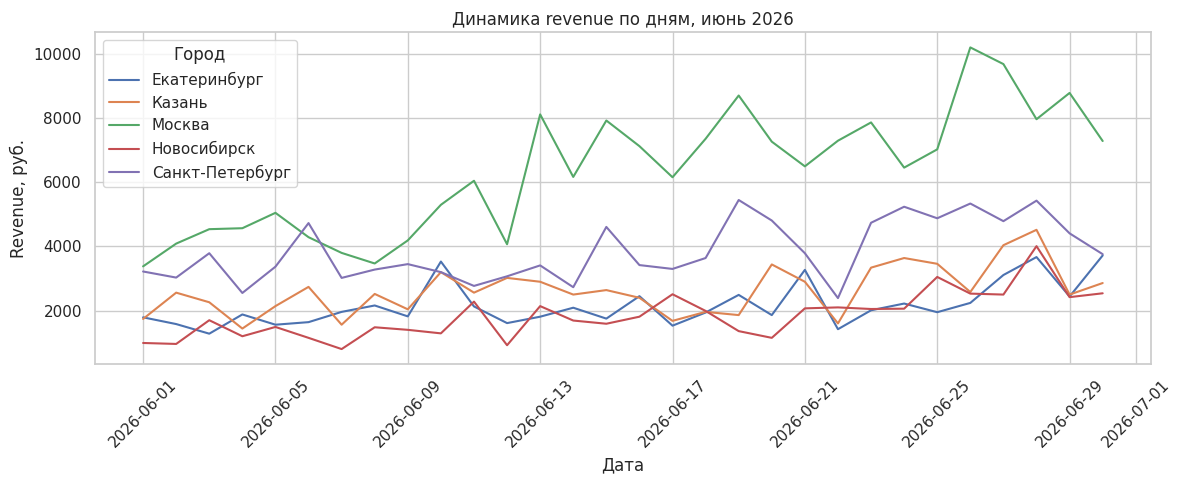

,revenue_start,revenue_end,abs_change,rel_change
city,,,,
Екатеринбург,11690.0,19350.0,7660.0,0.655261
Казань,14440.0,23600.0,9160.0,0.634349
Москва,29720.0,57440.0,27720.0,0.932705
Новосибирск,8290.0,19110.0,10820.0,1.305187
Санкт-Петербург,23710.0,33850.0,10140.0,0.427668


In [11]:
# Подневная динамика revenue и сравнение городов
df['date'] = df['event_timestamp'].dt.date
purchases = df[df['event_type'] == 'purchase']

daily_revenue = purchases.groupby(['date', 'city'])['revenue'].sum().unstack(fill_value=0)

daily_revenue.plot(figsize=(12, 5))
plt.title('Динамика revenue по дням, июнь 2026')
plt.xlabel('Дата')
plt.ylabel('Revenue, руб.')
plt.legend(title='Город')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

start_period = purchases[(purchases['date'] >= pd.Timestamp('2026-06-01').date()) & (purchases['date'] <= pd.Timestamp('2026-06-07').date())]
end_period = purchases[(purchases['date'] >= pd.Timestamp('2026-06-24').date()) & (purchases['date'] <= pd.Timestamp('2026-06-30').date())]

revenue_start = start_period.groupby('city')['revenue'].sum()
revenue_end = end_period.groupby('city')['revenue'].sum()

city_growth = pd.DataFrame({
    'revenue_start': revenue_start,
    'revenue_end': revenue_end
})

city_growth['abs_change'] = city_growth['revenue_end'] - city_growth['revenue_start']
city_growth['rel_change'] = city_growth['abs_change'] / city_growth['revenue_start']

city_growth





### Обоснование выбора периодов

Сравниваются два периода - первая неделя месяца (01.06 - 07.06) и последняя неделя месяца (24.06-30.06).
Периоды сопоставимы, так как у них одинаковая длина, они не пересекаются, оба описывают целую неделю (будни+выходные), что корректно для сравнения

### Выводы

Лидер абсолютного роста - Москва (+27 720 руб.).
Лидер относительного роста - Новосибирск (+130,5%), хотя прирост в рублях (+10 820) значительно меньше московского

Различие ответов связано с тем, что относительное изменение зависит от начальных значений. Абсолютный прирост показывает какой город получил больше денег, а относительный - какой город быстрее всего растет относительно себя. У Новосибирска начальная `revenue` была меньше, поэтому сопоставимый и даже меньший абсолютный прирост дает больший относительный рост.


## Задание 3. Сравните покупателей Москвы и Казани

Сравните поведение пользователей Москвы и Казани, которые совершили хотя бы одну покупку за месяц.

Для каждого покупателя рассчитайте revenue за месяц и количество визитов. Затем сравните города по двум показателям:

- средняя revenue на покупателя
- среднее количество визитов в приложение на покупателя

Чтобы описать различия подробнее, для каждой пользовательской метрики рассчитайте среднее, медиану, дисперсию, 25-й и 75-й квантили, минимум и максимум. При желании дополните описание гистограммами или boxplot-ами.

Опишите, какие различия между покупателями Москвы и Казани вы обнаружили.

число покупателей по городам:
city
Москва    75
Казань    35
Name: count, dtype: int64

---revenue---
           mean  median         var     q25     q75    min     max
city                                                              
Казань  2245.71  2300.0  1372789.92  1360.0  2900.0  480.0  5980.0
Москва  2543.47  2250.0  1877868.90  1420.0  3535.0  230.0  7040.0

---visits---
        mean  median   var  q25   q75  min  max
city                                           
Казань  8.86     8.0  7.18  7.0  11.0    4   14
Москва  9.32     9.0  7.33  7.5  11.0    3   17



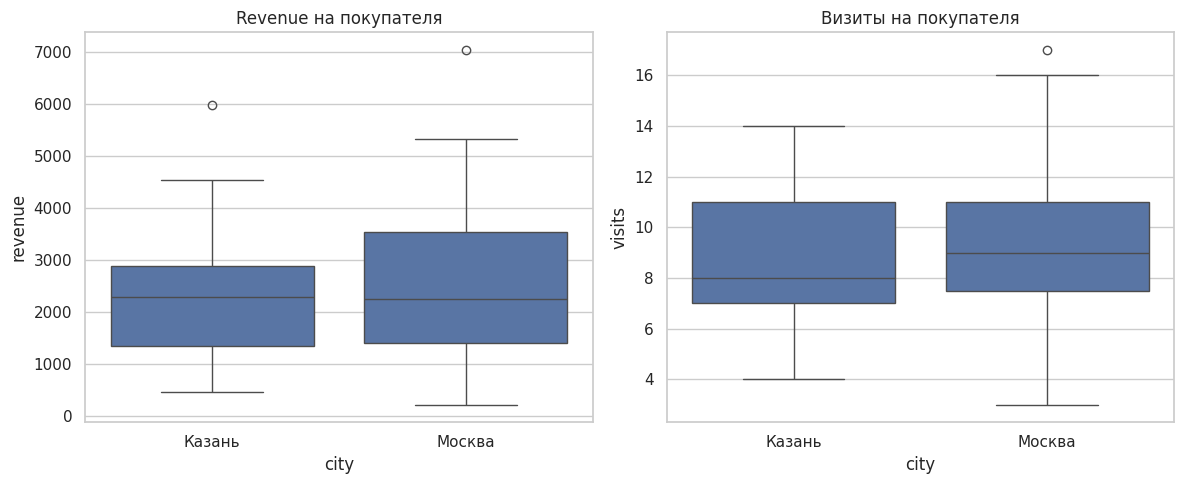

In [12]:
# Сравнение покупателей Москвы и Казани
cities = ['Москва', 'Казань']
sub = df[df['city'].isin(cities)]

buyers_ids = sub.loc[sub['event_type'] == 'purchase', 'user_id'].unique()
sub_buyers = sub[sub['user_id'].isin(buyers_ids)]

revenue_per_buyer = sub_buyers[sub_buyers['event_type'] == 'purchase'].groupby('user_id')['revenue'].sum()
visits_per_buyer = sub_buyers[sub_buyers['event_type'] == 'visit'].groupby('user_id').size()
buyer_city = sub_buyers.drop_duplicates('user_id').set_index('user_id')['city']

buyer_stats = pd.DataFrame({
    'revenue': revenue_per_buyer,
    'visits': visits_per_buyer.reindex(revenue_per_buyer.index).fillna(0)
})
buyer_stats['city'] = buyer_city.reindex(buyer_stats.index)

print('число покупателей по городам:')
print(buyer_stats['city'].value_counts())
print()

for metric in ['revenue', 'visits']:
  print(f'---{metric}---')
  desc = buyer_stats.groupby('city')[metric].agg(mean='mean', median='median', var='var',
                                                 q25=lambda x: x.quantile(0.25), q75=lambda x:
                                                 x.quantile(0.75), min='min', max='max')
  print(desc.round(2))
  print()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(data=buyer_stats, x='city', y='revenue', ax=axes[0])
axes[0].set_title('Revenue на покупателя')
sns.boxplot(data=buyer_stats, x='city', y='visits', ax=axes[1])
axes[1].set_title('Визиты на покупателя')
plt.tight_layout()
plt.show()







### Выводы

Средняя revenue на покупателя выше в Москве (2 543 руб.), чем в Казани (2 246 руб.), но медианы почти совпадают (2 250 руб. в Москве и 2 300 руб. в Казани). Значит, типичный покупатель в обоих городах тратит примерно одинаково, а более высокое среднее в Москве создают отдельные крупные покупки: максимум revenue в Москве — 7 040 руб. против 5 980 руб. в Казани, дисперсия в Москве заметно выше (≈1,88 млн против ≈1,37 млн).

По числу визитов города похожи: среднее в Москве 9,3, в Казани 8,9, медианы 9 и 8 визитов соответственно, дисперсия тоже сопоставима (≈7,3). То есть основное различие между городами не в частоте визитов, а в наличии в Москве более "дорогих" покупателей, которые вытягивают среднюю revenue вверх.

## Задание 4. Есть ли связь между активностью пользователя и revenue?

Команда «Мякушки» хочет понять, связана ли активность пользователя в приложении с revenue.

В этом задании рассматривайте всех пользователей, которые хотя бы раз заходили в приложение за месяц.

- Постройте scatter plot количества визитов и revenue каждого пользователя
- Рассчитайте коэффициент корреляции Пирсона
- Проинтерпретируйте полученные результаты и ответьте на вопрос команды, обозначив ограничения анализа

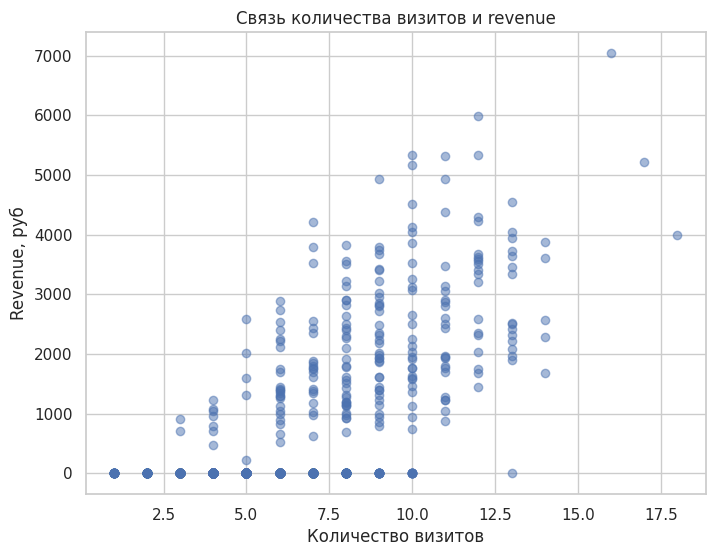

Коэффициент корреляции Пирсона: 0.683
Доля пользователей с revenue = 0: 74.9 %


In [15]:
# Связь активности и revenue

visitor_ids = df.loc[df['event_type'] == 'visit', 'user_id'].unique()
sub = df[df['user_id'].isin(visitor_ids)]

visits = sub[sub['event_type'] == 'visit'].groupby('user_id').size()
revenue_by_user = sub[sub['event_type'] == 'purchase'].groupby('user_id')['revenue'].sum()

user_stats = pd.DataFrame({'visits': visits}).join(revenue_by_user.rename('revenue'), how='left')
user_stats['revenue'] = user_stats['revenue'].fillna(0)

plt.figure(figsize=(8, 6))
plt.scatter(user_stats['visits'], user_stats['revenue'], alpha=0.5)
plt.xlabel('Количество визитов')
plt.ylabel('Revenue, руб')
plt.title('Связь количества визитов и revenue')
plt.show()

corr = user_stats['visits'].corr(user_stats['revenue'])
print('Коэффициент корреляции Пирсона:', round(corr, 3))

print('Доля пользователей с revenue = 0:', round((user_stats['revenue'] == 0).mean() * 100, 1), '%')







### Выводы

Были посчитаны число визитов и суммарное `revenue` для всех пользователей, кто хотя бы раз заходил в приложение. Получен коэффициент корреляции Пирсона = 0,683, что позволяет сделать вывод, что пользователи, которые чаще заходят в приложение, в среднем тратят больше.
Но доля пользователей с `revenue` = 0 равна 74,9% при этом количество визитов у них от 0 до ~12,5. Также есть пользователи, у которых большая revenue при большой активности, они могли завысить результаты.
Таким образом, связь между активностью и revenue есть, но этого показателя недостаточно, чтобы утверждать, что если увеличим число визитов, то увеличится revenue.